# Notebook description

In this notebook, there will be an experimental approach for a new model. This model incorporates data augmentation techniques during training to investigate whether increasing visual diversity can improve detection performance and model generalization.

The model retains the 960-pixel input resolution and the original class configuration, allowing the evaluation of augmentation effects on both PPE presence and absence-related categories.

# Dataset import

Imports and versions

In [ ]:
!pip install -q ultralytics

import ultralytics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics.data.utils import check_det_dataset
import os
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from collections import Counter


print("Ultralytics version:", ultralytics.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Ultralytics version: 8.4.211
NumPy version: 2.4.6
Pandas version: 2.2.3


Chack data and create paths

In [ ]:
data = check_det_dataset("construction-ppe.yaml")
print("Dataset downloaded and verified")

dataset_path = Path(data["path"])
print("Dataset path:", dataset_path)

print("Number of classes:", data["nc"])
print("Class names:", data["names"])

train_img_path = Path(data["train"])
print("Training images:", train_img_path)

val_img_path = Path(data["val"])
print("Validation images:", val_img_path)

Dataset downloaded and verified
Dataset path: /content/datasets/construction-ppe
Number of classes: 12
Class names: {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'Person', 6: 'no_helmet', 7: 'no_goggle', 8: 'no_gloves', 9: 'no_boots', 10: 'forklift', 11: 'no_vest'}
Training images: /content/datasets/construction-ppe/images/train
Validation images: /content/datasets/construction-ppe/images/val


# Data augmentation

In [ ]:
!pip install -q -U albumentations pyyaml opencv-python-headless

import albumentations as A
import cv2
import numpy as np
import os
import shutil
import yaml

from pathlib import Path
from tqdm.notebook import tqdm


transform = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.7
    ),

    A.RandomGamma(
        gamma_limit=(80, 120),
        p=0.3
    ),

    A.CLAHE(
        clip_limit=2.0,
        p=0.2
    ),

    A.RandomShadow(
        p=0.3
    ),

    A.HueSaturationValue(
        hue_shift_limit=5,
        sat_shift_limit=15,
        val_shift_limit=10,
        p=0.3
    ),

    A.GaussNoise(
        p=0.2
    ),

    A.GaussianBlur(
        blur_limit=(3, 5),
        p=0.15
    ),

], bbox_params=A.BboxParams(
    format="yolo",
    label_fields=["class_labels"]
))

/usr/local/lib/python3.13/dist-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


In [ ]:
dataset_path = Path(
    "/content/datasets/construction-ppe"
)

output_path = Path(
    "/content/datasets/construction-ppe-augmented"
)

num_augmentations = 2

In [ ]:
def load_yolo_labels(label_path):

    boxes = []
    class_labels = []

    if not label_path.exists():
        return boxes, class_labels

    with open(label_path, "r") as f:

        for line in f:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            bbox = list(map(float, values[1:]))

            boxes.append(bbox)
            class_labels.append(class_id)

    return boxes, class_labels

In [ ]:
def save_yolo_labels(label_path, boxes, class_labels):

    with open(label_path, "w") as f:

        for bbox, class_id in zip(boxes, class_labels):

            values = [class_id] + list(bbox)

            f.write(
                " ".join(map(str, values)) + "\n"
            )

In [ ]:
def clip_yolo_bbox(bbox):

    x, y, w, h = bbox

    x_min = max(0.0, x - w / 2)
    y_min = max(0.0, y - h / 2)

    x_max = min(1.0, x + w / 2)
    y_max = min(1.0, y + h / 2)

    new_x = (x_min + x_max) / 2
    new_y = (y_min + y_max) / 2

    new_w = x_max - x_min
    new_h = y_max - y_min

    return [new_x, new_y, new_w, new_h]

In [ ]:
for folder in [
    "images/train",
    "labels/train",
    "images/val",
    "labels/val"
]:
    (output_path / folder).mkdir(
        parents=True,
        exist_ok=True
    )


shutil.copytree(
    dataset_path / "images/val",
    output_path / "images/val",
    dirs_exist_ok=True
)

shutil.copytree(
    dataset_path / "labels/val",
    output_path / "labels/val",
    dirs_exist_ok=True
)

image_dir = dataset_path / "images/train"
label_dir = dataset_path / "labels/train"

output_images = output_path / "images/train"
output_labels = output_path / "labels/train"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_files = [
    p for p in image_dir.iterdir()
    if p.suffix.lower() in image_extensions
]


for image_path in tqdm(image_files):

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    image = cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

    label_path = label_dir / f"{image_path.stem}.txt"

    boxes, class_labels = load_yolo_labels(label_path)

    boxes = [
      clip_yolo_bbox(bbox)
      for bbox in boxes
    ]

    shutil.copy2(
        image_path,
        output_images / image_path.name
    )

    if label_path.exists():
        shutil.copy2(
            label_path,
            output_labels / label_path.name
        )

    for i in range(num_augmentations):

        augmented = transform(
            image=image,
            bboxes=boxes,
            class_labels=class_labels
        )

        aug_image = cv2.cvtColor(
            augmented["image"],
            cv2.COLOR_RGB2BGR
        )

        aug_boxes = augmented["bboxes"]
        aug_classes = augmented["class_labels"]

        new_name = f"{image_path.stem}_aug{i+1}"

        cv2.imwrite(
            str(output_images / f"{new_name}{image_path.suffix}"),
            aug_image
        )


        save_yolo_labels(
            output_labels / f"{new_name}.txt",
            aug_boxes,
            aug_classes
        )

print("Data augmentation completed")

  0%|          | 0/800 [00:00<?, ?it/s]

Data augmentation completed


New class distribution

In [ ]:
print("Output path:", output_path)
print("Train labels:", (output_path / "labels/train").exists())
print("Val labels:", (output_path / "labels/val").exists())

print("Train files:", len(list((output_path / "labels/train").glob("*.txt"))))
print("Val files:", len(list((output_path / "labels/val").glob("*.txt"))))

Output path: /content/datasets/construction-ppe-augmented
Train labels: True
Val labels: True
Train files: 2400
Val files: 200


In [ ]:
from collections import Counter

class_names = {
    0: 'helmet',
    1: 'gloves',
    2: 'vest',
    3: 'boots',
    4: 'goggles',
    5: 'Person',
    6: 'no_helmet',
    7: 'no_goggle',
    8: 'no_gloves',
    9: 'no_boots',
    10: 'forklift',
    11: 'no_vest'
}


def count_instances(split):

    labels_dir = output_path / "labels" / split

    counts = Counter()

    for file in labels_dir.glob("*.txt"):

        with open(file, "r") as f:

            for line in f:

                values = line.strip().split()

                if values:
                    class_id = int(float(values[0]))
                    counts[class_id] += 1

    return counts


train_counts = count_instances("train")
val_counts = count_instances("val")

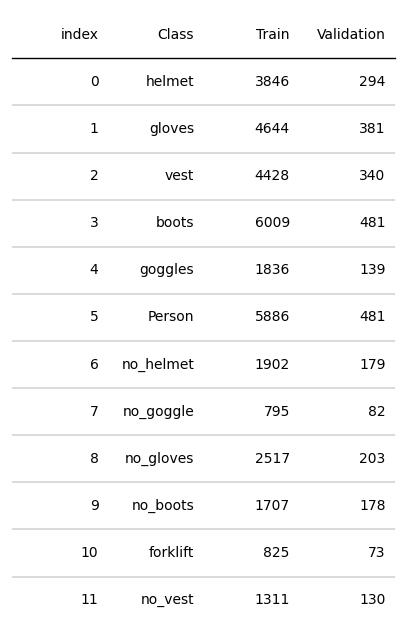

In [ ]:
!pip install plottable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plottable import Table

df = pd.DataFrame({
    "Class": list(class_names.values()),
    "Train": [train_counts[i] for i in class_names],
    "Validation": [val_counts[i] for i in class_names]
})

fig, ax = plt.subplots(figsize=(5, 8))
tab = Table(df)

plt.show()

In [ ]:

with open(dataset_path / "data.yaml", "r") as f:
    data = yaml.safe_load(f)


data["path"] = str(output_path)
data["train"] = "images/train"
data["val"] = "images/val"


with open(output_path / "data.yaml", "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(data)

{'path': '/content/datasets/construction-ppe-augmented', 'train': 'images/train', 'val': 'images/val', 'names': {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'Person', 6: 'no_helmet', 7: 'no_goggle', 8: 'no_gloves', 9: 'no_boots', 10: 'forklift', 11: 'no_vest'}}


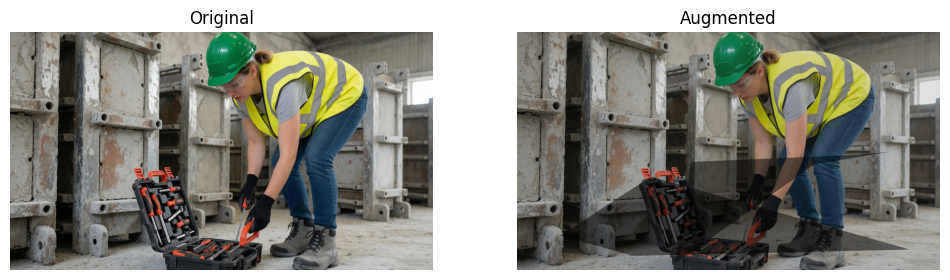

In [ ]:
import matplotlib.pyplot as plt

original = cv2.imread(
    str(output_images / image_files[100].name)
)

augmented = cv2.imread(
    str(output_images /
        f"{image_files[100].stem}_aug1{image_files[100].suffix}")
)

original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
augmented = cv2.cvtColor(augmented, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(original)
ax[0].set_title("Original")

ax[1].imshow(augmented)
ax[1].set_title("Augmented")

for a in ax:
    a.axis("off")

plt.show()

# Fine-tuning YOLO

## Model with data augmented adjusting brightness

### Training

In [ ]:
from ultralytics import YOLO

model2 = YOLO("yolo26n.pt")

yaml = str(output_path / "data.yaml")

results = model2.train(
    data=yaml,
    epochs=50,
    patience=20,
    imgsz=960,
    batch=16,
    device=0
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/construction-ppe-augmented/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=No

#### Evaluate and save weights

### Results

#### Plotted metrics

Mounted at /content/drive


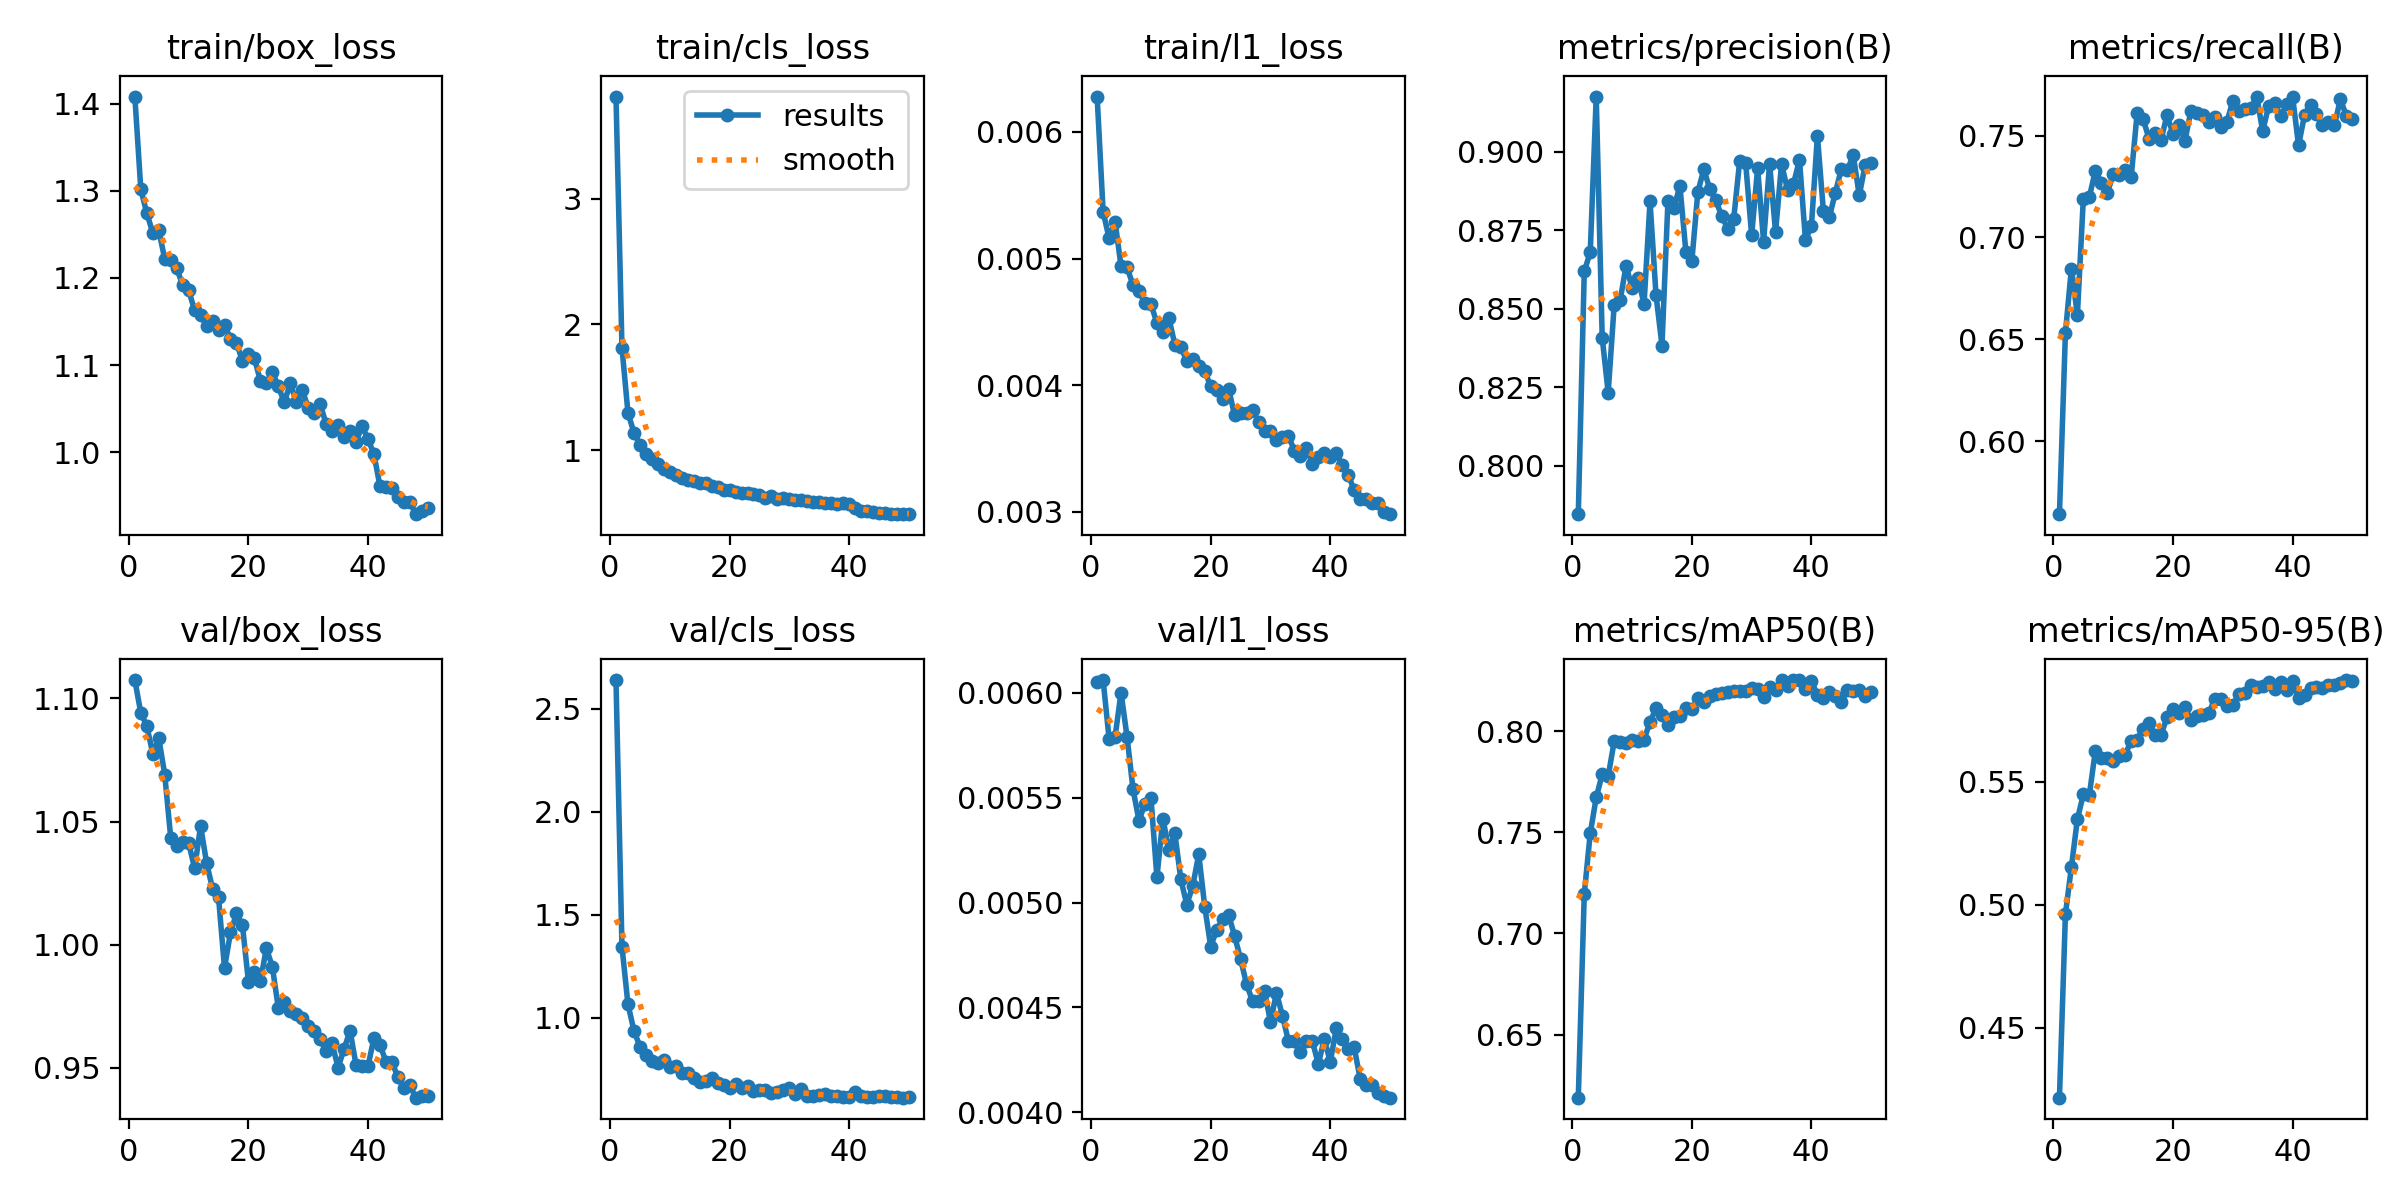

In [ ]:
from ultralytics import YOLO
from ultralytics.utils.plotting import plot_results
from google.colab import drive
from IPython.display import Image, display
import os
import shutil

drive.mount('/content/drive')

save_dir = results.save_dir

plot_results(file=os.path.join(save_dir, "results.csv"))

display(Image(filename=os.path.join(save_dir, "results.png")))


Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3421.1±645.8 MB/s, size: 830.4 KB)
val: Scanning /content/datasets/construction-ppe-augmented/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 69.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.6it/s 8.0s
                   all        200       2961      0.895      0.765      0.821      0.592
                helmet        146        294      0.951      0.867      0.918      0.734
                gloves        136        381      0.921      0.795      0.852      0.664
                  vest        157        340      0.971      0.915      0.938      0.769
                 boots        155        481      0.864      0.752      0.837      0.653
               gog

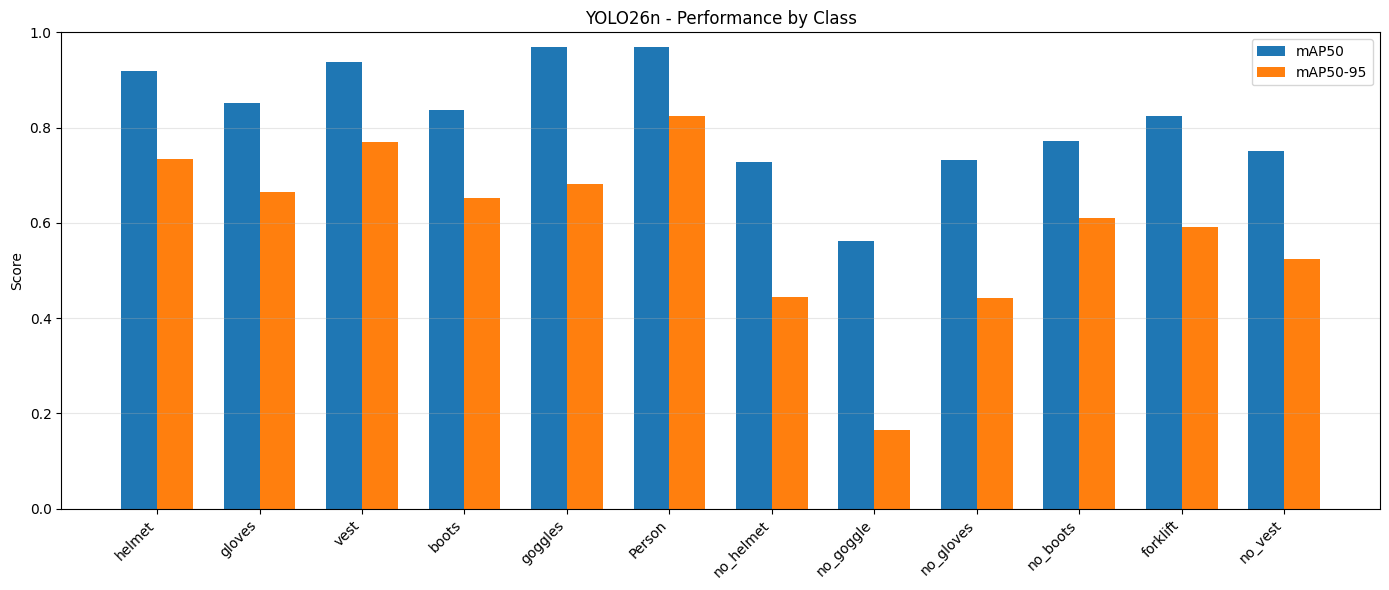

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

modelweights = YOLO(
    os.path.join(save_dir, "weights", "best.pt")
)

metrics = modelweights.val(
    data=yaml,
    imgsz=960
)

names = metrics.names
class_ids = metrics.box.ap_class_index

class_names = [names[int(i)] for i in class_ids]

map50 = metrics.box.ap50
map5095 = metrics.box.maps

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, map50, width, label="mAP50")
plt.bar(x + width/2, map5095, width, label="mAP50-95")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Performance by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

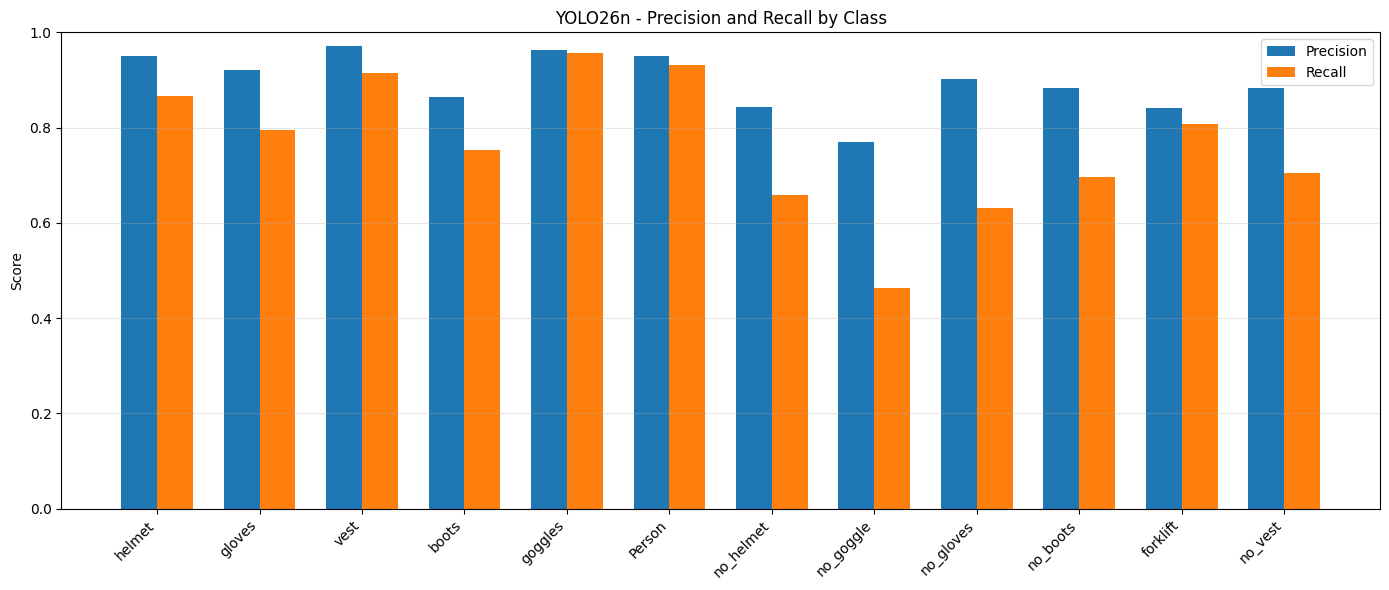

In [ ]:
precision = metrics.box.p
recall = metrics.box.r

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, precision, width, label="Precision")
plt.bar(x + width/2, recall, width, label="Recall")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Precision and Recall by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Visualize predictions

In [ ]:
import glob

label_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_labels.jpg")
)

pred_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_pred.jpg")
)

for label, pred in zip(sorted(label_images), sorted(pred_images)):

    print("Ground Truth")
    display(Image(filename=label))

    print("Predictions")
    display(Image(filename=pred))

Output hidden; open in https://colab.research.google.com to view.

#### Save weights

In [ ]:
destination = "/content/drive/MyDrive/PPE_Construction_YOLO/weights"

os.makedirs(destination, exist_ok=True)

shutil.copy(
    os.path.join(save_dir, "weights", "best.pt"),
    os.path.join(destination, "model3.pt")
)

print("Saved files:", os.listdir(destination))

Saved files: ['last.pt', 'best.pt', 'model1.pt', 'model3.pt']


## Test

In [ ]:
from ultralytics import YOLO

In [ ]:
model = YOLO(
    "/content/drive/MyDrive/PPE_Construction_YOLO/weights/model3.pt"
)

In [ ]:
video_path = "/content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4"

In [ ]:
test = model.predict(
    source=video_path,
    imgsz=960,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/PPE_Construction_YOLO",
    name="video_predictions",
    exist_ok=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/145) /content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4: 544x960 2 helmets, 1 gloves, 2 vests, 1 boots, 3 Persons, 9.4ms
video 1/1 (frame 2/145) /content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4: 544x960 2 helmets, 1 gloves, 2 vests, 1 boots, 3 Persons, 16.1ms
video 1/1 (frame 3/145) /content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4: 544x960 1 helmet, 1 gloves, 2 vests, 2 bootss, 1 Person, 18.4ms
video 1/

In [ ]:
import glob
import os
import subprocess

output_dir = "/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions"

video_files = glob.glob(os.path.join(output_dir, "*.avi")) + \
              glob.glob(os.path.join(output_dir, "*.mp4"))

print(video_files)

['/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video1.avi', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video1_converted.mp4']


In [ ]:
input_video = video_files[0]
converted_video = os.path.join(output_dir, "video3_converted.mp4")

subprocess.run([
    "ffmpeg", "-y",
    "-i", input_video,
    "-vcodec", "libx264",
    "-pix_fmt", "yuv420p",
    "-an",
    converted_video
], check=True)

CompletedProcess(args=['ffmpeg', '-y', '-i', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video1.avi', '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', '-an', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video3_converted.mp4'], returncode=0)

In [ ]:
from IPython.display import Video, display

display(Video(converted_video, embed=True, width=800))

Output hidden; open in https://colab.research.google.com to view.

# Observations

Data augmentation resulted in a slight improvement in overall detection performance, particularly in mAP50-95, suggesting a modest improvement in bounding box localization.

At the class level, no_goggle showed a noticeable improvement in mAP50, increasing from 0.477 to 0.554. However, its recall and mAP50-95 remained relatively low, indicating persistent difficulties in detecting and accurately localizing this category.

Furthermore, improvements were not consistent across all classes, suggesting that data augmentation alone may not fully address the limitations associated with absence-related categories.

These findings motivated the exploration of an alternative problem formulation focused exclusively on PPE presence.